# Ensemble Learning for Sri Lankan Used-Car Prices
### Bagging vs Boosting vs Stacking vs Hybrid (RF + ANN)

**Module:** Machine Learning and Pattern Recognition - Hands-On Ensemble Learning Project
**Student:** Vineth Nallaperuma
**Dataset:** SriLankan Vehicle (Car) Price Dataset - 9,788 listings scraped from **ikman.lk** and **Riyasewana.com** (Dec 2024 - Feb 2025), by Prasad Nirmal on Kaggle (MIT licence)

---

**Goal.** Predict the asking price of a used car in Sri Lanka from its make, model, age, engine, mileage, fuel, transmission, location and equipment, and compare the three ensemble paradigms plus one hybrid:

| Paradigm | Models in this notebook |
|---|---|
| Baselines (non-ensemble) | Ridge regression, single Decision Tree, SVR, ANN |
| **Bagging** | Random Forest |
| **Boosting** | XGBoost, LightGBM, CatBoost |
| **Stacking** | RF + LightGBM + CatBoost + SVR → Ridge meta-learner |
| **Hybrid** | Random Forest + ANN (residual hybrid) |

**Notebook outline**
1. Setup
2. Load and clean the data
3. Exploratory data analysis (including the effect of Sri Lanka's vehicle import ban)
4. Feature engineering
5. Train/test split and choice of evaluation metric
6. Preprocessing pipelines
7. Baselines → Bagging → Boosting → Stacking → Hybrid (each tuned with `GridSearchCV`)
8. Results comparison
9. Feature importance
10. Interpretation: why the models behaved this way on Sri Lankan data
11. Strengths, limitations and a reflection on tabular vs image/text data
12. Saving models for the dashboard
13. AI usage acknowledgment
14. Running the dashboard and references

> **How to run:** keep this notebook in the repository root next to `ml_utils.py` and the `data/` folder, then *Run All*. In Google Colab, first clone the repository and `pip install -r requirements.txt`. A full run takes about 15 minutes on a 2-core machine (most of it is hyperparameter tuning).

## 1. Setup

In [1]:
# !pip install -r requirements.txt   # uncomment on Google Colab

import json
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from lightgbm import LGBMRegressor
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error,
                             r2_score, root_mean_squared_error)
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

# Project helpers shared with the dashboard (app.py), so features are built identically
from ml_utils import (BAN_LIFT_DATE, FEATURES, CatBoostModel, RFANNHybrid, add_features,
                      clean_raw, make_ann_preprocessor, make_preprocessor)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="X does not have valid feature names")

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
for folder in ["models", "results", "figures"]:
    Path(folder).mkdir(exist_ok=True)

## 2. Load and clean the data

The data comes from two Sri Lankan marketplaces, **ikman.lk** and **Riyasewana.com**, so it is a genuinely local dataset (as required), not a US/international Kaggle set. Prices are asking prices in the dataset's own unit; values such as 43 for a typical car match **lakhs of rupees** (1 lakh = Rs 100,000), so that is how they are labelled here.

In [2]:
raw = pd.read_csv("data/vehicle_prices.csv")
print("Raw shape:", raw.shape)
raw.head()

Raw shape: (9788, 17)


,Unnamed: 0,Brand,Model,YOM,Engine (cc),Gear,Fuel Type,Millage(KM),Town,Date,Leasing,Condition,AIR CONDITION,POWER STEERING,POWER MIRROR,POWER WINDOW,Price
0,0,AUDI,A1,2016,990.0,Automatic,Petrol,99000.0,Gampaha,2025-02-05,No Leasing,USED,Available,Available,Available,Available,100.0
1,1,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2025-01-14,No Leasing,USED,Available,Available,Available,Available,97.0
2,2,AUDI,A1,2018,1000.0,Automatic,Petrol,77000.0,Dehiwala-Mount-Lavinia,2025-01-23,No Leasing,USED,Available,Available,Available,Available,98.5
3,3,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Negombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,107.0
4,4,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,99.5


In [3]:
print("Missing values per column:")
print(raw.isna().sum().to_string())
print("\nExact duplicate rows:", raw.drop(columns=["Unnamed: 0"]).duplicated().sum())

Missing values per column:
Unnamed: 0        0
Brand             0
Model             0
YOM               0
Engine (cc)       0
Gear              0
Fuel Type         0
Millage(KM)       0
Town              0
Date              0
Leasing           0
Condition         0
AIR CONDITION     0
POWER STEERING    0
POWER MIRROR      0
POWER WINDOW      0
Price             0

Exact duplicate rows: 18


There are **no missing values**, so no imputation is needed. There are **18 exact duplicates** (same car, same ad details). They are removed: a duplicate that lands in both the training and test set would let the model be tested on a car it has already seen, inflating the score.

`clean_raw()` (in `ml_utils.py`) renames columns to `snake_case`, trims and upper-cases text, and drops duplicates.

In [4]:
df = clean_raw(raw)
print(f"Removed {len(raw) - len(df)} duplicates -> {len(df):,} listings")
df.describe().round(1)

Removed 18 duplicates -> 9,770 listings


,yom,engine_cc,mileage_km,price
count,9770.0,9770.0,9770.0,9770.0
mean,2006.8,1260.7,200730.3,53.5
std,9.8,403.8,108164.2,43.6
min,1956.0,573.0,11000.0,2.6
25%,2001.0,1000.0,110000.0,26.2
50%,2009.0,1300.0,176000.0,43.0
75%,2015.0,1500.0,264000.0,69.8
max,2024.0,4800.0,759000.0,790.0


### Outlier check
Rule used: **remove values that are clearly errors, keep values that are rare but real.** Luxury cars at Rs 400-600 lakhs are real and the model should learn about them.

In [5]:
cols = ["brand", "model", "yom", "engine_cc", "mileage_km", "price"]
print("Cheapest listings:")
display(df.nsmallest(4, "price")[cols])
print("Most expensive listings:")
display(df.nlargest(6, "price")[cols])

Cheapest listings:


,brand,model,yom,engine_cc,mileage_km,price
8386,TOYOTA,KE50,1980,1400.0,495000.0,2.65
2100,MITSUBISHI,COLT,1979,1400.0,506000.0,3.25
2128,MITSUBISHI,GALANT,1975,1500.0,550000.0,3.40
2485,NISSAN,B310,1979,1400.0,506000.0,3.65


Most expensive listings:


,brand,model,yom,engine_cc,mileage_km,price
8402,TOYOTA,LEXUS 600HL,2011,600.0,154000.0,790.0
137,BMW,740LE M SPORT,2016,2000.0,99000.0,575.0
1773,MERCEDES-BENZ,S400 LONG WHEEL BASE,2015,3500.0,110000.0,550.0
55,AUDI,Q4,2024,1500.0,11000.0,475.0
132,BMW,530I M SPORT,2017,2200.0,88000.0,460.0
108,BMW,430I GRAN COUPE,2017,2000.0,88000.0,450.0


In [6]:
# A 600 cc engine is impossible for a Lexus LS 600h (a 5-litre V8 hybrid); "600" was entered as the engine size.
# Electric cars are excluded from this check: they have no engine, so their engine_cc is just a placeholder.
suspicious = df[(df["price"] > 300) & (df["engine_cc"] < 1000) & (df["fuel_type"] != "Electric")]
display(suspicious[cols])
df = df.drop(suspicious.index).reset_index(drop=True)
print(f"Dropped {len(suspicious)} clearly erroneous row(s) -> {len(df):,} listings")

,brand,model,yom,engine_cc,mileage_km,price
8402,TOYOTA,LEXUS 600HL,2011,600.0,154000.0,790.0


Dropped 1 clearly erroneous row(s) -> 9,769 listings


The very cheap cars are genuine 1970s-80s vehicles with 400,000-550,000 km, so they stay. Other data-quality issues are noted as limitations rather than "fixed" by hand (for example, some listings put a non-Toyota model such as *LADA RIVA* under the Toyota brand). Because the data was scraped from user-written ads, some noise like this is unavoidable.

## 3. Exploratory data analysis

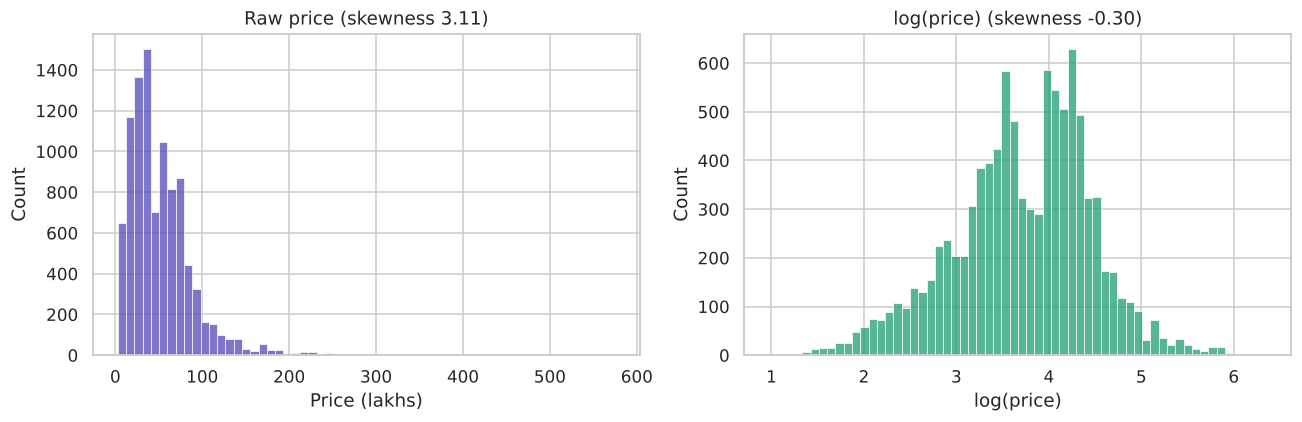

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["price"], bins=60, ax=axes[0], color="#534AB7")
axes[0].set(title=f"Raw price (skewness {df['price'].skew():.2f})", xlabel="Price (lakhs)")
sns.histplot(np.log(df["price"]), bins=60, ax=axes[1], color="#1D9E75")
axes[1].set(title=f"log(price) (skewness {np.log(df['price']).skew():.2f})", xlabel="log(price)")
plt.tight_layout(); plt.savefig("figures/price_distribution.png"); plt.show()

**Observation.** Raw prices are heavily right-skewed: most cars cost under 80 lakhs, with a long tail of luxury cars. With a squared-error loss, a few expensive cars would dominate training. After a **log transform** the distribution is roughly symmetric, so **all models in this notebook are trained on `log(price)`** and predictions are converted back with `exp()`. This also means each model is effectively minimising *relative* (percentage) error, which is fair to both cheap and expensive cars.

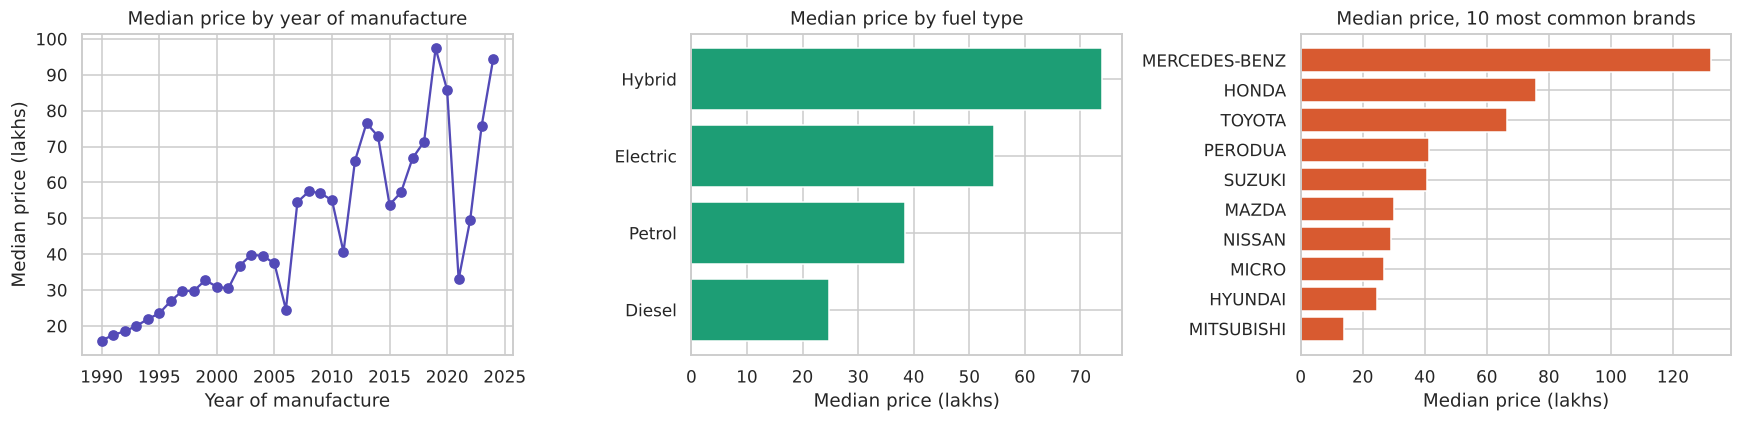

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
by_year = df[df["yom"] >= 1990].groupby("yom")["price"].median()
axes[0].plot(by_year.index, by_year.values, marker="o", color="#534AB7")
axes[0].set(title="Median price by year of manufacture", xlabel="Year of manufacture", ylabel="Median price (lakhs)")

fuel = df.groupby("fuel_type")["price"].median().sort_values()
axes[1].barh(fuel.index, fuel.values, color="#1D9E75")
axes[1].set(title="Median price by fuel type", xlabel="Median price (lakhs)")

top_brands = df["brand"].value_counts().head(10).index
brand = df[df["brand"].isin(top_brands)].groupby("brand")["price"].median().sort_values()
axes[2].barh(brand.index, brand.values, color="#D85A30")
axes[2].set(title="Median price, 10 most common brands", xlabel="Median price (lakhs)")
plt.tight_layout(); plt.savefig("figures/eda_price_drivers.png"); plt.show()

**Observations.**
- Price rises steeply with year of manufacture: newer cars are worth far more, so **age** should be the strongest predictor.
- Hybrids and electric cars sell for more than petrol cars, partly because they are newer on average.
- Brand matters a lot (premium European brands vs budget Japanese/Indian kei cars), and within a brand the **model** matters even more.

### Sri Lanka-specific context: the vehicle import ban
Sri Lanka suspended vehicle imports in **March 2020** (COVID-19, then the 2022 foreign-exchange crisis and debt default). Imports of personal vehicles were allowed again from **1 February 2025**, with high new import taxes. Used-car prices rose sharply during the ban because no new stock could enter the country. This dataset was scraped exactly around that turning point.

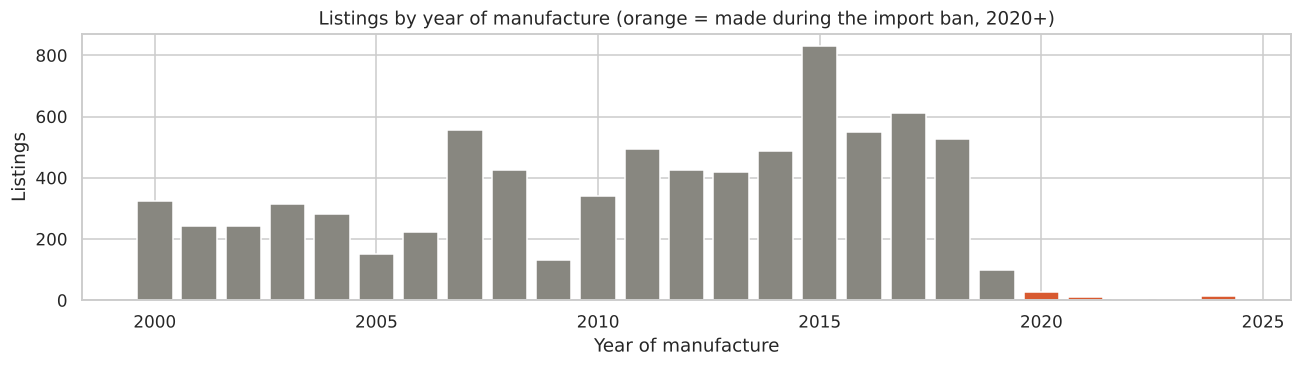

Cars made 2020 or later: 58 of 9769


,listings,median_price,median_yom
Listed before 1 Feb 2025,7339,42.75,2009.0
Listed on/after 1 Feb 2025 (ban lifted),2430,43.75,2009.0


In [9]:
fig, ax = plt.subplots(figsize=(12, 3.5))
counts = df[df["yom"] >= 2000]["yom"].value_counts().sort_index()
ax.bar(counts.index, counts.values, color=["#D85A30" if yr >= 2020 else "#888780" for yr in counts.index])
ax.set(title="Listings by year of manufacture (orange = made during the import ban, 2020+)",
       xlabel="Year of manufacture", ylabel="Listings")
plt.tight_layout(); plt.savefig("figures/import_ban_listings.png"); plt.show()

print("Cars made 2020 or later:", (df["yom"] >= 2020).sum(), "of", len(df))
after = pd.to_datetime(df["date"]) >= BAN_LIFT_DATE
summary = df.assign(after_ban=after).groupby("after_ban").agg(
    listings=("price", "size"), median_price=("price", "median"), median_yom=("yom", "median"))
summary.index = ["Listed before 1 Feb 2025", "Listed on/after 1 Feb 2025 (ban lifted)"]
summary

**Observations.**
- Only a few dozen cars in the whole dataset were made in 2020 or later: the ban stopped almost all new cars from entering the country. **Models will have very little data to learn about the newest cars**, so we should expect larger errors for them (checked in Section 8).
- About a quarter of the listings were posted after the ban was lifted. Their median asking price was **not lower**, which suggests sellers had not yet cut prices in the first days after the announcement (the new imports were also heavily taxed). The flag is kept as a feature so the models can use any difference that does exist.

## 4. Feature engineering
`add_features()` (in `ml_utils.py`, shared with the dashboard) creates:

| New feature | Why |
|---|---|
| `age` = 2025 − year of manufacture | Same information as the year, but reads naturally ("10 years old") |
| `listed_after_ban` | 1 if the ad was posted on or after 1 Feb 2025 (import ban lifted) |
| equipment flags | "Available"/"Not_Available" → 1/0 |

The raw `date` column is not used directly.

**Inflation was deliberately not added.** All ads were posted within the same two months, so a "listing-year inflation" column would be identical for almost every row, and an "inflation in the year of manufacture" column would just be a relabelled copy of `yom`. Neither adds information the models don't already have.

### A data-quality discovery: mileage is not real
A natural engineered feature is **km per year** (mileage ÷ age): 50,000 km on a 10-year-old car is very different from 300,000 km. Computing it revealed something important:

In [10]:
df = add_features(df)
km_per_year = df["mileage_km"] / df["age"]
print(km_per_year.describe().round(1).to_string())
print("\nCorrelation between mileage and age:", round(df["mileage_km"].corr(df["age"]), 6))
display(df[["yom", "age", "mileage_km"]].drop_duplicates("yom").sort_values("yom", ascending=False).head(6))

count     9769.0
mean     11000.0
std          0.0
min      11000.0
25%      11000.0
50%      11000.0
75%      11000.0
max      11000.0

Correlation between mileage and age: 1.0


,yom,age,mileage_km
55,2024,1,11000.0
1809,2023,2,22000.0
1458,2022,3,33000.0
1300,2021,4,44000.0
155,2020,5,55000.0
23,2019,6,66000.0


**Every single car has exactly 11,000 km per year** (standard deviation 0), and mileage correlates perfectly with age. In other words, the mileage column in this dataset was **filled in by the dataset creator as age × 11,000 km**; it is not the odometer reading from the ad.

Consequences:
- `mileage_km` carries **no information beyond age**, and `km_per_year` is a constant. Both are **dropped** from the model features. Keeping mileage would only split the importance of "age" across two identical columns and make the feature-importance charts misleading.
- In reality, mileage is one of the most important price factors for a used car. This is a genuine **limitation of the dataset**: the models cannot learn how heavy use lowers a car's value, and some of the remaining error comes from this missing information.

Final numeric features: age, engine size, the ban flag and the four equipment flags.

In [11]:
print("Correlation of numeric features with log(price):")
num = ["age", "engine_cc", "listed_after_ban", "air_condition", "power_steering", "power_mirror", "power_window"]
print(df[num].corrwith(np.log(df["price"])).sort_values().round(3).to_string())

Correlation of numeric features with log(price):
age                -0.701
listed_after_ban    0.018
engine_cc           0.063
air_condition       0.197
power_steering      0.414
power_window        0.531
power_mirror        0.534


## 5. Train/test split and evaluation metric

The data is split **before** any preprocessing is learned (80% train / 20% test). Every encoder and scaler is fitted on the training data only, inside a `Pipeline`, so no information from the test set leaks into training, even inside each cross-validation fold.

**Choice of metric (regression):**
- **Primary: RMSE on log(price).** Because errors are measured on the log scale, this is close to an average *percentage* error, so a 10% miss counts the same for a Rs 10-lakh Alto and a Rs 300-lakh BMW. RMSE (rather than MAE) still penalises large misses more, which matters because badly mispricing a car is costly for a buyer or seller. This is also the score used by `GridSearchCV` for tuning.
- **MAE in lakhs:** the easiest to explain ("on average the prediction is off by Rs X lakhs").
- **R²:** the share of price variation the model explains (1.0 = perfect), reported on both the log and the original scale.
- **MAPE:** mean absolute percentage error, for an intuitive "% off".

Recall / precision / SMOTE are not used: they apply to **classification**, and this is a **regression** problem with no classes to balance.

In [12]:
X = df[FEATURES]
y = np.log(df["price"])  # train on log(price)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f"Train: {len(X_train):,} listings | Test: {len(X_test):,} listings | Features: {len(FEATURES)}")
print(FEATURES)

Train: 7,815 listings | Test: 1,954 listings | Features: 14
['model', 'brand', 'gear', 'fuel_type', 'leasing', 'condition', 'town', 'age', 'engine_cc', 'listed_after_ban', 'air_condition', 'power_steering', 'power_mirror', 'power_window']


## 6. Preprocessing pipelines
Each model is a `Pipeline(preprocessor → model)`, defined in `ml_utils.make_preprocessor()`:

| Column type | Treatment | Why |
|---|---|---|
| `model` (1,555 distinct values; most appear < 5 times) | **Target encoding**: replaced by the average log-price of that model in the training data, learned with internal 5-fold cross-fitting | One-hot would create 1,555 mostly-empty columns. Cross-fitting stops a row's own price leaking into its encoding. |
| brand, gear, fuel, leasing, condition, town | **One-hot encoding**, values seen fewer than 10 times grouped as "infrequent" | Few values each; no fake ordering |
| numeric features | **StandardScaler** for SVR, ANN and Ridge; left unscaled for tree models | Distance- and gradient-based models need comparable scales; tree splits don't care about units |

**CatBoost** is the exception: it receives the raw text categories and handles them itself with its own leakage-safe "ordered target statistics".

In [13]:
results, fitted, tuning = {}, {}, {}
cv3 = KFold(n_splits=3, shuffle=True, random_state=SEED)

def evaluate(name, model, seconds, family):
    # Score a fitted model on the test set (and train set, to check overfitting)
    pred_test = model.predict(X_test)
    pred_train = model.predict(X_train)
    true_lakhs, pred_lakhs = np.exp(y_test), np.exp(pred_test)
    results[name] = {
        "family": family,
        "RMSE_log": root_mean_squared_error(y_test, pred_test),
        "R2_log": r2_score(y_test, pred_test),
        "MAE_lakhs": mean_absolute_error(true_lakhs, pred_lakhs),
        "RMSE_lakhs": root_mean_squared_error(true_lakhs, pred_lakhs),
        "R2_lakhs": r2_score(true_lakhs, pred_lakhs),
        "MAPE_pct": 100 * mean_absolute_percentage_error(true_lakhs, pred_lakhs),
        "train_R2_log": r2_score(y_train, pred_train),
        "seconds": seconds,
    }
    fitted[name] = model
    return pd.Series(results[name]).drop("family").astype(float).round(3)

def tune(name, estimator, grid, family, n_jobs=1):
    # GridSearchCV with 3-fold CV on the training set, scored by RMSE on log(price)
    start = time.time()
    search = GridSearchCV(estimator, grid, scoring="neg_root_mean_squared_error", cv=cv3, n_jobs=n_jobs)
    search.fit(X_train, y_train)
    tuning[name] = {"best_params": {k.split("__")[-1]: v for k, v in search.best_params_.items()},
                    "cv_RMSE_log": -search.best_score_,
                    "candidates": len(search.cv_results_["params"])}
    print(f"{name}: tried {tuning[name]['candidates']} settings | best CV RMSE_log = {-search.best_score_:.4f}")
    print("  best params:", tuning[name]["best_params"])
    return evaluate(name, search.best_estimator_, time.time() - start, family)

## 7. Models

### 7.1 Baselines (non-ensemble)
Baselines show how much the ensembles actually add. **Ridge regression** is a linear model (a straight-line fit with a penalty on large weights). A **single decision tree** is the building block that every ensemble below is made of.

In [14]:
tune("Ridge (linear)",
     Pipeline([("prep", make_preprocessor(scale=True)), ("model", Ridge())]),
     {"model__alpha": [0.1, 1, 10]}, family="Baseline")

Ridge (linear): tried 3 settings | best CV RMSE_log = 0.2616
  best params: {'alpha': 1}


RMSE_log         0.245
R2_log           0.892
MAE_lakhs        8.830
RMSE_lakhs      20.286
R2_lakhs         0.791
MAPE_pct        17.268
train_R2_log     0.911
seconds          0.589
dtype: float64

In [15]:
tune("Decision Tree",
     Pipeline([("prep", make_preprocessor(scale=False)), ("model", DecisionTreeRegressor(random_state=SEED))]),
     {"model__max_depth": [8, 12, 16, None], "model__min_samples_leaf": [1, 5, 10]}, family="Baseline")

Decision Tree: tried 12 settings | best CV RMSE_log = 0.2557
  best params: {'max_depth': 16, 'min_samples_leaf': 10}


RMSE_log         0.257
R2_log           0.882
MAE_lakhs        7.182
RMSE_lakhs      18.769
R2_lakhs         0.821
MAPE_pct        15.431
train_R2_log     0.938
seconds          2.788
dtype: float64

### 7.2 Bagging: Random Forest
Hundreds of deep trees, each trained on a bootstrap sample of the rows and considering a random subset of features (`max_features`) at each split; predictions are averaged. Averaging cancels out the individual trees' overfitting (variance reduction).

**Deployment constraint:** a forest of 300 fully grown trees (`min_samples_leaf=1`) saved to disk was close to 50 MB, and the Stacking and Hybrid models each contain another copy of the forest, which pushed the stacking file above GitHub's 100 MB limit. The grid therefore uses 200 trees and `min_samples_leaf` ≥ 2. A separate check showed this costs very little accuracy (test RMSE_log 0.210 with 300 fully grown trees vs 0.213 here), and leaves of at least 2 cars also act as light pre-pruning.

In [16]:
tune("Random Forest",
     Pipeline([("prep", make_preprocessor(scale=False)),
               ("model", RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=SEED))]),
     {"model__max_features": [0.33, 0.5, "sqrt"], "model__min_samples_leaf": [2, 3, 5]},
     family="Bagging")

Random Forest: tried 9 settings | best CV RMSE_log = 0.2195
  best params: {'max_features': 0.5, 'min_samples_leaf': 2}


RMSE_log         0.213
R2_log           0.919
MAE_lakhs        5.430
RMSE_lakhs      13.738
R2_lakhs         0.904
MAPE_pct        12.362
train_R2_log     0.966
seconds         27.250
dtype: float64

### 7.3 Boosting: XGBoost, LightGBM, CatBoost
Shallow trees are added **one after another**, each fitted to the errors (gradients of the loss) left by the previous ones, scaled by a `learning_rate`. This mainly reduces bias.

- **XGBoost**: regularised gradient boosting with level-wise tree growth.
- **LightGBM**: histogram-based, grows trees **leaf-wise** (`num_leaves`), very fast.
- **CatBoost**: symmetric (oblivious) trees and **native categorical handling**.

In [17]:
tune("XGBoost",
     Pipeline([("prep", make_preprocessor(scale=False)),
               ("model", XGBRegressor(subsample=0.8, colsample_bytree=0.8, n_jobs=2, random_state=SEED))]),
     {"model__n_estimators": [600, 1000], "model__max_depth": [4, 6, 8], "model__learning_rate": [0.03, 0.06]},
     family="Boosting")

XGBoost: tried 12 settings | best CV RMSE_log = 0.2156
  best params: {'learning_rate': 0.03, 'max_depth': 8, 'n_estimators': 600}


RMSE_log         0.201
R2_log           0.928
MAE_lakhs        5.456
RMSE_lakhs      12.629
R2_lakhs         0.919
MAPE_pct        12.101
train_R2_log     0.977
seconds         30.394
dtype: float64

In [18]:
tune("LightGBM",
     Pipeline([("prep", make_preprocessor(scale=False)),
               ("model", LGBMRegressor(subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                       n_jobs=2, random_state=SEED, verbose=-1))]),
     {"model__n_estimators": [600, 1000], "model__num_leaves": [15, 31, 63], "model__learning_rate": [0.03, 0.06]},
     family="Boosting")

LightGBM: tried 12 settings | best CV RMSE_log = 0.2206
  best params: {'learning_rate': 0.03, 'n_estimators': 600, 'num_leaves': 63}


RMSE_log         0.208
R2_log           0.923
MAE_lakhs        5.705
RMSE_lakhs      13.206
R2_lakhs         0.911
MAPE_pct        12.812
train_R2_log     0.968
seconds         31.204
dtype: float64

In [19]:
tune("CatBoost", CatBoostModel(iterations=1000),
     {"depth": [6, 8], "learning_rate": [0.05, 0.1]}, family="Boosting")

CatBoost: tried 4 settings | best CV RMSE_log = 0.2273
  best params: {'depth': 8, 'learning_rate': 0.1}


RMSE_log         0.207
R2_log           0.923
MAE_lakhs        5.861
RMSE_lakhs      12.837
R2_lakhs         0.916
MAPE_pct        13.133
train_R2_log     0.956
seconds         57.218
dtype: float64

### 7.4 A non-tree model for diversity: Support Vector Regression
SVR is tuned on its own first because it is one of the stacking base models. It is a completely different kind of model (kernel-based, distance-driven), which is exactly what stacking needs: base models that make *different* mistakes.

In [20]:
tune("SVR",
     Pipeline([("prep", make_preprocessor(scale=True)), ("model", SVR(kernel="rbf"))]),
     {"model__C": [1, 3, 10], "model__epsilon": [0.05, 0.1]}, family="Baseline", n_jobs=2)

SVR: tried 6 settings | best CV RMSE_log = 0.2371
  best params: {'C': 1, 'epsilon': 0.05}


RMSE_log         0.210
R2_log           0.921
MAE_lakhs        6.678
RMSE_lakhs      16.194
R2_lakhs         0.867
MAPE_pct        13.936
train_R2_log     0.946
seconds         29.371
dtype: float64

### 7.5 Stacking
The tuned **Random Forest, LightGBM, CatBoost and SVR** become base models. `StackingRegressor` generates their **out-of-fold** predictions with 5-fold CV (so the meta-learner never sees predictions a model made on its own training rows), and a **RidgeCV** meta-learner learns how much to trust each one.

In [21]:
# clone() = same tuned settings, but unfitted (StackingRegressor refits them itself; this also
# avoids storing a second copy of every fitted model inside the saved stacking file)
base_models = [
    ("rf", clone(fitted["Random Forest"])),
    ("lgbm", clone(fitted["LightGBM"])),
    ("catboost", clone(fitted["CatBoost"])),
    ("svr", clone(fitted["SVR"])),
]
start = time.time()
stack = StackingRegressor(estimators=base_models, final_estimator=RidgeCV(alphas=[0.01, 0.1, 1, 10]),
                          cv=KFold(5, shuffle=True, random_state=SEED), n_jobs=1)
stack.fit(X_train, y_train)
display(evaluate("Stacking", stack, time.time() - start, family="Stacking"))
weights = pd.Series(stack.final_estimator_.coef_, index=[n for n, _ in base_models]).round(3)
print("Meta-learner weights:"); print(weights.to_string())

RMSE_log         0.195
R2_log           0.932
MAE_lakhs        5.280
RMSE_lakhs      12.426
R2_lakhs         0.921
MAPE_pct        11.897
train_R2_log     0.967
seconds         68.125
dtype: float64

Meta-learner weights:
rf          0.327
lgbm        0.224
catboost    0.356
svr         0.105


### 7.6 Hybrid: Random Forest + ANN
For tabular regression the brief suggests combining Random Forest with an Artificial Neural Network. This notebook uses a **residual hybrid**:

1. The tuned Random Forest predicts `log(price)`.
2. A small ANN (`MLPRegressor`) receives the features **plus the RF prediction** and learns to predict the **RF's error** (residual).
3. Final prediction = RF prediction + ANN correction.

The ANN is trained on **out-of-fold** RF predictions (`cross_val_predict`), so it learns from the forest's realistic errors on unseen data rather than its near-perfect fit on training rows. The ANN is small (one hidden layer of 32 neurons) and strongly regularised (`alpha=0.1`, early stopping) because it only needs to learn a correction.

For comparison, the ANN is also trained **on its own**.

In [22]:
tune("ANN (MLP)",
     Pipeline([("prep", make_preprocessor(scale=True)),
               ("model", MLPRegressor(early_stopping=True, max_iter=1000, random_state=SEED))]),
     {"model__hidden_layer_sizes": [(32,), (64, 32)], "model__alpha": [0.001, 0.1]}, family="Baseline")

ANN (MLP): tried 4 settings | best CV RMSE_log = 0.2444
  best params: {'alpha': 0.1, 'hidden_layer_sizes': (32,)}


RMSE_log         0.222
R2_log           0.911
MAE_lakhs        7.491
RMSE_lakhs      16.993
R2_lakhs         0.853
MAPE_pct        15.326
train_R2_log     0.933
seconds         11.888
dtype: float64

In [23]:
ann_corrector = Pipeline([("prep", make_ann_preprocessor()),
                          ("model", MLPRegressor(hidden_layer_sizes=(32,), alpha=0.1, early_stopping=True,
                                                 max_iter=1000, random_state=SEED))])
start = time.time()
hybrid = RFANNHybrid(rf_pipeline=clone(fitted["Random Forest"]), ann_pipeline=ann_corrector, cv=5)
hybrid.fit(X_train, y_train)
evaluate("Hybrid RF + ANN", hybrid, time.time() - start, family="Hybrid")

RMSE_log         0.207
R2_log           0.923
MAE_lakhs        5.598
RMSE_lakhs      12.818
R2_lakhs         0.916
MAPE_pct        12.843
train_R2_log     0.949
seconds         11.216
dtype: float64

## 8. Results comparison

In [24]:
res = pd.DataFrame(results).T
num_cols = [c for c in res.columns if c != "family"]
res[num_cols] = res[num_cols].astype(float)
res = res.sort_values("RMSE_log")
res["overfit_gap"] = res["train_R2_log"] - res["R2_log"]
display(res.style.format({c: "{:.3f}" for c in num_cols + ["overfit_gap"]} | {"seconds": "{:.0f}", "MAPE_pct": "{:.1f}"})
        .background_gradient(subset=["RMSE_log", "MAE_lakhs", "MAPE_pct"], cmap="Greens_r")
        .background_gradient(subset=["R2_log", "R2_lakhs"], cmap="Greens"))

,family,RMSE_log,R2_log,MAE_lakhs,RMSE_lakhs,R2_lakhs,MAPE_pct,train_R2_log,seconds,overfit_gap
Stacking,Stacking,0.195,0.932,5.280,12.426,0.921,11.9,0.967,68,0.036
XGBoost,Boosting,0.201,0.928,5.456,12.629,0.919,12.1,0.977,30,0.049
CatBoost,Boosting,0.207,0.923,5.861,12.837,0.916,13.1,0.956,57,0.033
Hybrid RF + ANN,Hybrid,0.207,0.923,5.598,12.818,0.916,12.8,0.949,11,0.026
LightGBM,Boosting,0.208,0.923,5.705,13.206,0.911,12.8,0.968,31,0.045
SVR,Baseline,0.210,0.921,6.678,16.194,0.867,13.9,0.946,29,0.025
Random Forest,Bagging,0.213,0.919,5.430,13.738,0.904,12.4,0.966,27,0.048
ANN (MLP),Baseline,0.222,0.911,7.491,16.993,0.853,15.3,0.933,12,0.022
Ridge (linear),Baseline,0.245,0.892,8.830,20.286,0.791,17.3,0.911,1,0.019
Decision Tree,Baseline,0.257,0.882,7.182,18.769,0.821,15.4,0.938,3,0.056


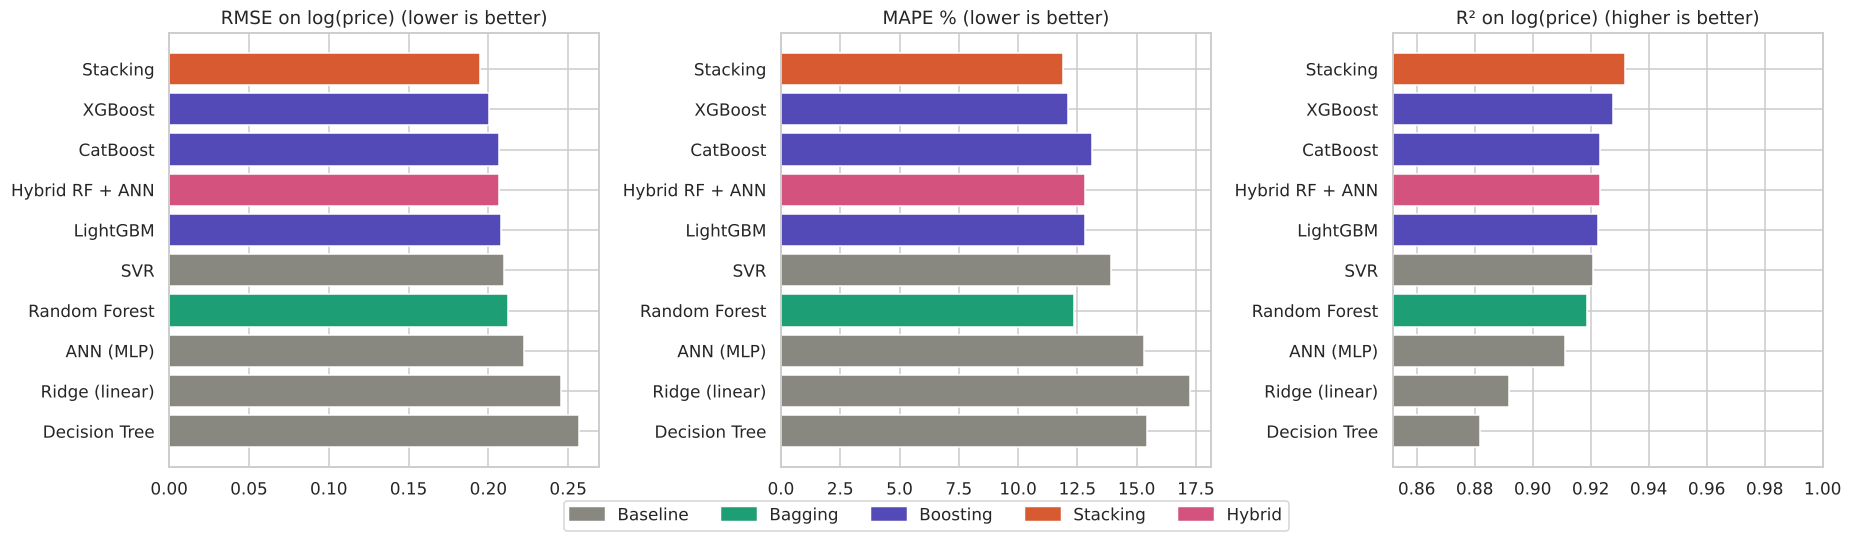

In [25]:
palette = {"Baseline": "#888780", "Bagging": "#1D9E75", "Boosting": "#534AB7", "Stacking": "#D85A30", "Hybrid": "#D4537E"}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
order = res.index[::-1]
for ax, metric, label in [(axes[0], "RMSE_log", "RMSE on log(price) (lower is better)"),
                          (axes[1], "MAPE_pct", "MAPE % (lower is better)"),
                          (axes[2], "R2_log", "R² on log(price) (higher is better)")]:
    ax.barh(order, res.loc[order, metric], color=[palette[f] for f in res.loc[order, "family"]])
    ax.set(title=label)
axes[2].set_xlim(res["R2_log"].min() - 0.03, 1)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()]
fig.legend(handles, palette.keys(), loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(); plt.savefig("figures/model_comparison.png", bbox_inches="tight"); plt.show()

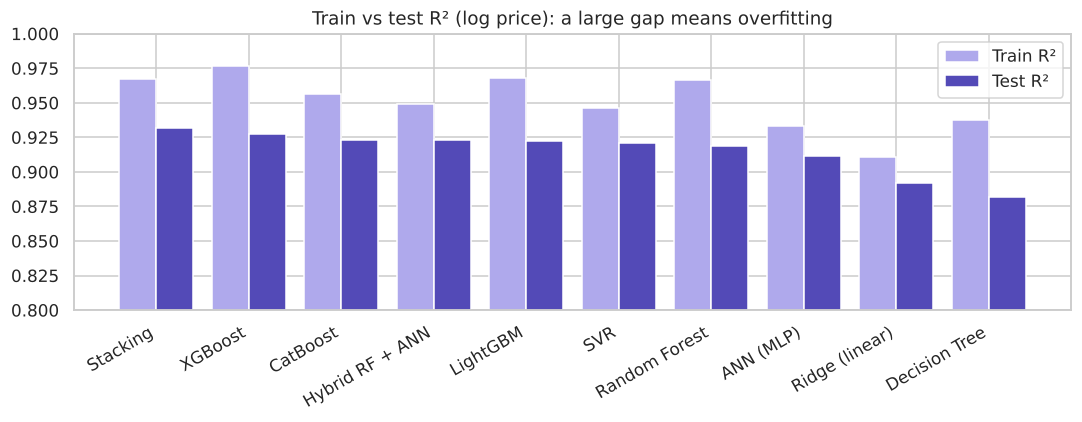

Tuning results (3-fold CV on the training set):


,best_params,cv_RMSE_log,candidates
Ridge (linear),{'alpha': 1},0.26162,3
Decision Tree,"{'max_depth': 16, 'min_samples_leaf': 10}",0.255691,12
Random Forest,"{'max_features': 0.5, 'min_samples_leaf': 2}",0.21951,9
XGBoost,"{'learning_rate': 0.03, 'max_depth': 8, 'n_est...",0.21562,12
LightGBM,"{'learning_rate': 0.03, 'n_estimators': 600, '...",0.22059,12
CatBoost,"{'depth': 8, 'learning_rate': 0.1}",0.227265,4
SVR,"{'C': 1, 'epsilon': 0.05}",0.2371,6
ANN (MLP),"{'alpha': 0.1, 'hidden_layer_sizes': (32,)}",0.244413,4


In [26]:
# Overfitting check: train vs test R² (log scale)
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(res))
ax.bar(x - 0.2, res["train_R2_log"], 0.4, label="Train R²", color="#AFA9EC")
ax.bar(x + 0.2, res["R2_log"], 0.4, label="Test R²", color="#534AB7")
ax.set_xticks(x, res.index, rotation=30, ha="right"); ax.set_ylim(0.8, 1.0)
ax.set(title="Train vs test R² (log price): a large gap means overfitting"); ax.legend()
plt.tight_layout(); plt.savefig("figures/overfitting_check.png"); plt.show()
print("Tuning results (3-fold CV on the training set):")
display(pd.DataFrame(tuning).T)

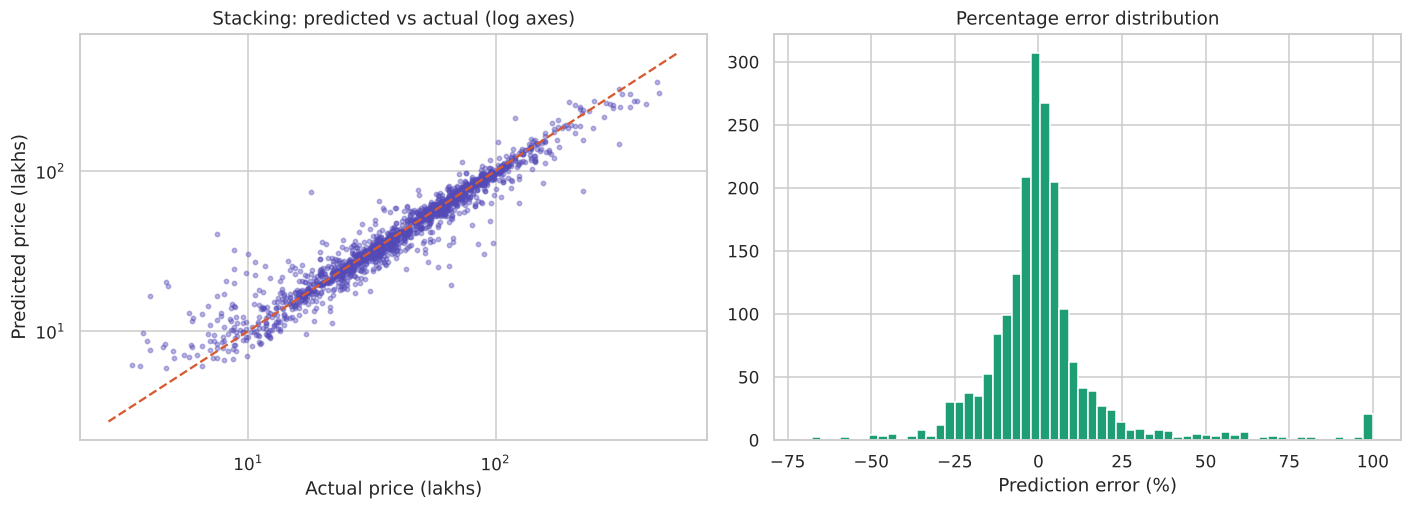

Stacking: 68% of test cars predicted within ±10%, 85% within ±20%


In [27]:
best_name = res.index[0]
best_pred = np.exp(fitted[best_name].predict(X_test))
true = np.exp(y_test)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].scatter(true, best_pred, s=8, alpha=0.4, color="#534AB7")
lims = [true.min() * 0.8, true.max() * 1.2]
axes[0].plot(lims, lims, "--", color="#D85A30"); axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set(title=f"{best_name}: predicted vs actual (log axes)", xlabel="Actual price (lakhs)", ylabel="Predicted price (lakhs)")
pct_err = 100 * (best_pred - true) / true
axes[1].hist(pct_err.clip(-100, 100), bins=60, color="#1D9E75")
axes[1].set(title="Percentage error distribution", xlabel="Prediction error (%)")
plt.tight_layout(); plt.savefig("figures/best_model_predictions.png"); plt.show()
print(f"{best_name}: {np.mean(np.abs(pct_err) <= 10):.0%} of test cars predicted within ±10%, "
      f"{np.mean(np.abs(pct_err) <= 20):.0%} within ±20%")

In [28]:
# Where do the models struggle? Error by car age (newest cars were scarce during the import ban)
bins = [0, 5, 10, 20, 100]
labels = ["1-5 yrs (2020+)", "6-10 yrs", "11-20 yrs", "20+ yrs"]
age_group = pd.cut(X_test["age"], bins=bins, labels=labels)
rows = {}
for name in ["Ridge (linear)", "Random Forest", "XGBoost", "CatBoost", "Stacking", "Hybrid RF + ANN"]:
    pred = np.exp(fitted[name].predict(X_test))
    ape = 100 * np.abs(pred - true) / true
    rows[name] = ape.groupby(age_group, observed=False).median()
by_age = pd.DataFrame(rows).T
by_age.loc["(test cars in group)"] = age_group.value_counts().reindex(labels)
print("Median absolute % error by car age:")
by_age.round(1)

Median absolute % error by car age:


age,1-5 yrs (2020+),6-10 yrs,11-20 yrs,20+ yrs
Ridge (linear),37.6,8.9,9.6,14.7
Random Forest,5.8,3.6,3.8,10.0
XGBoost,5.4,4.4,4.5,10.1
CatBoost,17.7,4.9,5.0,11.7
Stacking,12.6,4.0,4.3,10.5
Hybrid RF + ANN,14.8,4.6,4.6,11.1
(test cars in group),9.0,529.0,733.0,683.0


## 9. Feature importance

Two complementary views:
1. **Built-in importance** of each tree ensemble (how much each feature reduced the loss across all splits). These are computed on the *encoded* columns.
2. **Permutation importance** on the test set: shuffle one original feature at a time and measure how much RMSE gets worse. This works for **every** model (including Stacking and the Hybrid) and is measured on the original features, so the models can be compared directly. This is also what the dashboard displays.

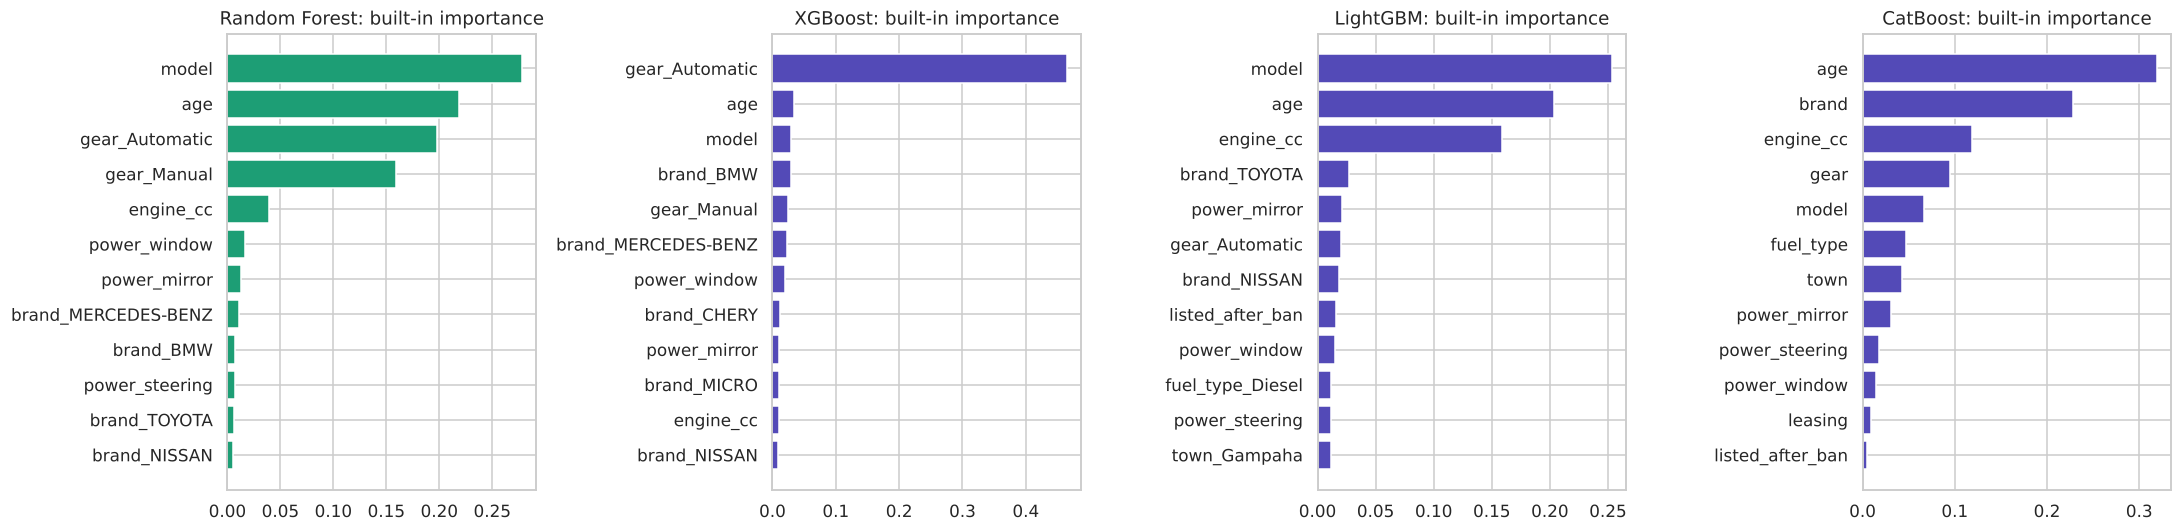

In [29]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, name in zip(axes, ["Random Forest", "XGBoost", "LightGBM", "CatBoost"]):
    model = fitted[name]
    if name == "CatBoost":
        imp = pd.Series(model.feature_importances_, index=FEATURES)
    else:
        names = model.named_steps["prep"].get_feature_names_out()
        imp = pd.Series(model.named_steps["model"].feature_importances_, index=names)
    imp = (imp / imp.sum()).sort_values().tail(12)
    ax.barh(imp.index, imp.values, color=palette[results[name]["family"]])
    ax.set(title=f"{name}: built-in importance")
plt.tight_layout(); plt.savefig("figures/builtin_importance.png"); plt.show()

Random Forest: done in 6s


XGBoost: done in 2s


LightGBM: done in 6s


CatBoost: done in 1s


Stacking: done in 102s


Hybrid RF + ANN: done in 8s


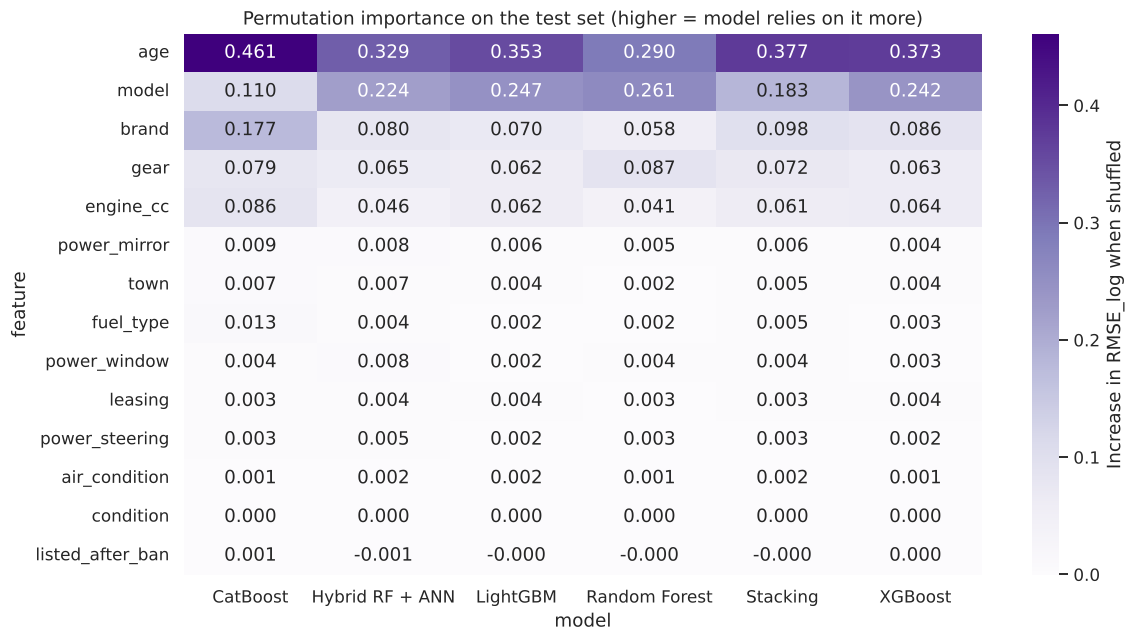

In [30]:
perm_rows = []
for name in ["Random Forest", "XGBoost", "LightGBM", "CatBoost", "Stacking", "Hybrid RF + ANN"]:
    t = time.time()
    pi = permutation_importance(fitted[name], X_test, y_test, scoring="neg_root_mean_squared_error",
                                n_repeats=5, random_state=SEED, n_jobs=1)
    for feat, mean, std in zip(FEATURES, pi.importances_mean, pi.importances_std):
        perm_rows.append({"model": name, "feature": feat, "importance": mean, "std": std})
    print(f"{name}: done in {time.time() - t:.0f}s")
perm = pd.DataFrame(perm_rows)
pivot = perm.pivot(index="feature", columns="model", values="importance")
pivot = pivot.loc[pivot.mean(axis=1).sort_values(ascending=False).index]
plt.figure(figsize=(11, 6))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="Purples", cbar_kws={"label": "Increase in RMSE_log when shuffled"})
plt.title("Permutation importance on the test set (higher = model relies on it more)")
plt.tight_layout(); plt.savefig("figures/permutation_importance.png"); plt.show()

## 10. Interpretation: why the models behaved this way on Sri Lankan car data

### 10.1 Summary of results (test set, 1,954 cars)

| Rank | Model | Family | RMSE (log) | R² (log) | MAPE | MAE (lakhs) |
|---|---|---|---|---|---|---|
| 1 | Stacking | Stacking | **0.195** | **0.932** | **11.9%** | **5.28** |
| 2 | XGBoost | Boosting | 0.201 | 0.928 | 12.1% | 5.46 |
| 3 | CatBoost | Boosting | 0.207 | 0.923 | 13.1% | 5.86 |
| 3 | Hybrid RF + ANN | Hybrid | 0.207 | 0.923 | 12.8% | 5.60 |
| 5 | LightGBM | Boosting | 0.208 | 0.923 | 12.8% | 5.71 |
| 6 | SVR | single model | 0.210 | 0.921 | 13.9% | 6.68 |
| 7 | Random Forest | Bagging | 0.213 | 0.919 | 12.4% | 5.43 |
| 8 | ANN (MLP) | single model | 0.222 | 0.911 | 15.3% | 7.49 |
| 9 | Ridge (linear) | single model | 0.245 | 0.892 | 17.3% | 8.83 |
| 10 | Decision Tree | single model | 0.257 | 0.882 | 15.4% | 7.18 |

The best model, **Stacking, prices 68% of unseen cars within ±10% and 85% within ±20%** of their asking price.

A caution before reading too much into small gaps: differences of about 0.005 in RMSE (log) are within the noise of a single 80/20 split. The 3-fold cross-validation scores from tuning give a second opinion: XGBoost 0.216, Random Forest 0.220, LightGBM 0.221, CatBoost 0.227, SVR 0.237. So XGBoost is consistently the strongest single model and Random Forest is solidly in the top group in CV, even though it ranks 7th on this particular test split.

### 10.2 Every ensemble beat the single decision tree, and by a lot
The single tuned decision tree is the **worst** model (RMSE 0.257), while a Random Forest built from 200 of the same kind of tree cuts the error by **17%** (0.213) and raises R² from 0.882 to 0.919. The tree also has the largest train-test gap (0.056). This is exactly the variance problem from the theory: one deep tree memorises quirks of its training rows (for example, a single oddly priced Alto), and averaging many trees grown on different bootstrap samples cancels those quirks out.

### 10.3 Why boosting edged out bagging here
XGBoost (0.201) beat Random Forest (0.213) on the test set and in cross-validation. The reasons are tied to this dataset:
- **Price is driven by a few strong, smooth effects.** Age alone explains most of the variation (it is by far the most important feature for every model, Section 9), and depreciation follows a smooth curve. Boosting builds the prediction **additively**, one small correction at a time, so it can trace this curve and the brand/model adjustments on top of it very precisely. Bagging averages deep trees that each predict a "staircase", which is less precise for smooth relationships.
- **Boosting reduces bias on the hard cases.** Random Forest actually has the highest share of cars within ±10% (69%), so it is excellent on ordinary cars that resemble many others. Its weakness is larger misses on unusual cars: on cars priced at 150 lakhs or more its average error is 18.2%, against 17.4% for XGBoost and 16.2% for Stacking. Boosting focuses each new tree on what is still wrong, which is exactly those harder, rarer cars.

### 10.4 Comparing the three boosting libraries
- **XGBoost** was the best single model. With only 7,800 training rows, its regularised, depth-limited trees were a good fit.
- **LightGBM** grows trees leaf-wise, which is its big advantage on very large datasets (speed). On a dataset this small that advantage disappears and leaf-wise growth can overfit slightly; its train-test gap (0.045) is close to XGBoost's.
- **CatBoost** was expected to shine because of its native handling of the 1,555 car models. It did not beat XGBoost, for two reasons. First, the other models were given a strong, leakage-safe **target encoding** of the car model, so CatBoost's main advantage was already partly matched. Second, CatBoost's ordered target statistics are deliberately conservative on rare categories (most models appear fewer than 5 times), so it leaned on **brand** much more than the others (permutation importance 0.177 for brand vs 0.110 for model, the reverse of every other model). That makes it less precise for specific models but gave it the **smallest overfitting gap** of the boosting models (0.033). CatBoost was also tuned on the smallest grid (4 settings) because each fit is slower.

### 10.5 Why stacking was best overall
Stacking combines Random Forest, LightGBM, CatBoost and SVR through a Ridge meta-learner, with weights **CatBoost 0.36, Random Forest 0.33, LightGBM 0.22, SVR 0.11**. Notice that Random Forest gets the second-largest weight even though it was the weakest tree ensemble on its own: its errors are **different** from the boosting models' errors (bagging vs boosting make different kinds of mistakes), and combining models with uncorrelated errors is what makes stacking work. SVR, a completely different type of model, adds a little more diversity.

The gain is real but modest (RMSE 0.201 → 0.195, about 3% better than XGBoost), and it comes at a cost: the stacked model trains every base model 6 times (5 CV folds + final fit), is 41 MB on disk, and is by far the slowest to predict (computing its permutation importance took about 100 seconds, against 1-7 seconds for each individual model). For a production car-pricing app, XGBoost alone would be a reasonable trade-off; for maximum accuracy, stacking wins.

### 10.6 The RF + ANN hybrid: what the neural network added
- **ANN alone was weak** (RMSE 0.222, MAPE 15.3%), better only than the linear model and single tree. Neural networks need a lot of data and struggle with high-cardinality categorical features and sharp, step-like effects in tabular data (see Section 11).
- **The hybrid improved Random Forest** from 0.213 to 0.207 RMSE (log), raised R² in lakhs from 0.904 to 0.916, reduced RMSE in lakhs from 13.7 to 12.8, and had the **smallest overfitting gap of all ensembles** (0.026).
- However, its MAE and MAPE are **slightly worse** than plain RF (12.8% vs 12.4%). The ANN learned smooth corrections that fix the forest's **larger, systematic errors** (which dominate RMSE), but it also adds small noise to cars the forest already priced well (which shows up in MAE/MAPE). In other words, the hybrid makes fewer big mistakes at the cost of slightly less precision on easy cases.
- The design matters: the ANN was trained on **out-of-fold** RF predictions. Training it on the forest's in-sample predictions (which are almost perfect) would teach it nothing about real errors.

### 10.7 A surprise: SVR on the log scale
SVR scores well on the log scale (0.210, better than RF on this split) but poorly in rupees (R² 0.867 vs 0.904+ for the ensembles). Its RBF kernel produces very smooth predictions, which suits the many ordinary cars, but it badly under-prices the sparse luxury segment (21% average error on cars of 150 lakhs or more). In cross-validation it ranks below all tree ensembles (0.237). This is why it got the smallest stacking weight.

### 10.8 What drives Sri Lankan used-car prices (feature importance)
- **Age** is the dominant factor for every model.
- **Car model** and **brand** come next: within the same age, a Toyota Premio and a Suzuki Alto are worlds apart. Tree models with target encoding rely on the specific model; CatBoost relies more on brand.
- **Gear (automatic vs manual)** is surprisingly important. In Sri Lanka, manual cars are mostly older budget cars and vans, so transmission is a proxy for market segment.
- **Engine size** matters moderately.
- **Equipment flags, town, fuel and leasing** add very little once age, model and brand are known. Fuel type looked important in the EDA, but that was mostly because hybrids and EVs are newer cars; the models get that information from age and model instead.
- **`listed_after_ban` has zero importance.** Asking prices did not change in the first days after imports reopened on 1 Feb 2025, which matches the EDA (median 42.75 before vs 43.75 after). New imports were heavily taxed, so sellers had little reason to cut prices immediately. A dataset covering the following months would be needed to measure the ban's real effect.
- **Condition (new/used)** is zero: only 94 listings are "new", too few to matter.

### 10.9 Where the models fail, and why it is specific to Sri Lanka
- **Newest cars (2020+):** because of the 2020-2025 import ban, only 58 such cars exist in the whole dataset (9 in the test set). Errors for this group swing between 5% and 18% depending on the model, compared with about 4-5% for 6-20-year-old cars. Trees cannot extrapolate beyond what they have seen, and here they have seen almost nothing.
- **Cars over 20 years old:** median errors of 10-12% for every model. Prices of vintage and classic cars (1960s Austins, 1980s Toyotas) depend on condition, originality and rarity, none of which are in the data.
- **Missing mileage:** the dataset's mileage is synthetic (age × 11,000 km, Section 4), so real wear and tear is invisible to the models. This is likely the single biggest source of remaining error.
- **Asking prices, not sale prices,** scraped from user-written ads, with some mislabelled brands/models. Part of the error is noise no model could remove.

## 11. Strengths, limitations and a reflection on tabular vs image/text data

### Strengths and limitations of the ensembles in this project

| Model | Strengths seen here | Limitations seen here |
|---|---|---|
| Random Forest (bagging) | Robust, little tuning needed, best share of cars within ±10%, hard to overfit badly | Larger misses on rare/expensive cars; big model files (16.7 MB for 200 trees) |
| XGBoost / LightGBM (boosting) | Best single-model accuracy; small model files; fast | More hyperparameters to tune; can overfit without a low learning rate and depth limits |
| CatBoost (boosting) | Handles raw text categories natively; least overfitting among boosting models | Slower to train; conservative on rare categories |
| Stacking | Best overall accuracy by combining models with different errors | Most complex; slowest to train and predict; hardest to explain |
| Hybrid RF + ANN | Fewer large errors than RF; smallest train-test gap | Slightly worse on typical cars; two models to maintain |

**Limitations shared by all tree ensembles:**
- **Loss of interpretability.** A single decision tree reads like the rule base of an expert system ("IF made after 2012 AND brand = Toyota THEN ..."), but nobody can follow 200 trees or a stack of four models. Feature importance (Section 9) recovers only part of the "why".
- **No extrapolation.** A tree-based model can never predict a price outside the range of the training leaves. When Sri Lanka's post-ban imports (2025 models, new tax regime) reach the second-hand market, these models will need retraining.
- **They only know what is in the data.** Missing mileage, condition and service history cap how accurate any of them can be.

### Reflection: ensembles on tabular data vs image/text data
This project is a typical example of **tabular data**: each column has its own meaning (age, brand, engine size), the features are a mix of numbers and categories, and the relationship to price has sharp jumps (between brands, models, automatic vs manual). On such data, **tree-based ensembles are still the state of the art**. Large benchmark studies (Grinsztajn et al., 2022; Shwartz-Ziv & Armon, 2022) found that gradient-boosted trees and random forests usually match or beat deep neural networks on medium-sized tabular datasets, while training much faster. The suggested reasons match what happened here:
- Trees handle **irregular, step-like patterns** (a different price level per car model) naturally, whereas neural networks are biased towards smooth functions. Our ANN alone was the weakest non-linear model.
- Trees **ignore uninformative features** easily (equipment flags, town), whereas neural networks are hurt by them.
- Tabular datasets are often **small** (here 7,800 rows); deep learning typically needs far more data.

**Image and text data are the opposite.** A single pixel or a single character means almost nothing on its own; the information is in **spatial or sequential structure** (edges, shapes, word order, context). Tree ensembles split on one raw input value at a time, so they cannot discover these structures, and they perform poorly on raw images or text. Convolutional neural networks and transformers are designed to learn exactly these structures, so deep learning dominates there. Ensembles are still used for images and text, but as **ensembles of neural networks** (for example, averaging several CNNs), or by training gradient boosting on **features/embeddings extracted by a neural network**, rather than on the raw pixels or words.

## 12. Save models and results for the dashboard

In [31]:
model_files = {}
for name, model in fitted.items():
    slug = name.lower().replace(" + ", "_").replace(" ", "_").replace("(", "").replace(")", "")
    path = Path("models") / f"{slug}.pkl"
    joblib.dump(model, path, compress=3)
    model_files[name] = str(path)
    print(f"{path}: {path.stat().st_size / 1e6:.1f} MB")

res.reset_index(names="model").to_csv("results/metrics.csv", index=False)
perm.to_csv("results/permutation_importance.csv", index=False)

test_out = X_test.copy()
test_out["actual_price"] = np.exp(y_test)
for name, model in fitted.items():
    test_out[f"pred::{name}"] = np.exp(model.predict(X_test))
test_out.to_csv("results/test_predictions.csv", index=False)

brand_models = (df.groupby("brand")["model"].value_counts().rename("n").reset_index()
                .groupby("brand")["model"].apply(list).to_dict())
meta = {
    "dataset": "SriLankan Vehicle (Car) Price Dataset (ikman.lk + Riyasewana.com), Dec 2024 - Feb 2025",
    "rows_after_cleaning": int(len(df)), "train_rows": int(len(X_train)), "test_rows": int(len(X_test)),
    "best_model": best_name, "model_files": model_files,
    "tuning": {k: {"best_params": {p: (str(v) if not isinstance(v, (int, float)) else v) for p, v in d["best_params"].items()},
                   "cv_RMSE_log": d["cv_RMSE_log"], "candidates": d["candidates"]} for k, d in tuning.items()},
    "stacking_weights": weights.to_dict(),
    "brand_models": brand_models,
    "brands_by_count": df["brand"].value_counts().index.tolist(),
    "towns": df["town"].value_counts().index.tolist(),
    "options": {c: sorted(df[c].unique().tolist()) for c in ["gear", "fuel_type", "leasing", "condition"]},
    "ranges": {"yom": [int(df["yom"].min()), int(df["yom"].max())],
               "engine_cc": [int(df["engine_cc"].min()), int(df["engine_cc"].max())],
               "mileage_km": [int(df["mileage_km"].min()), int(df["mileage_km"].max())]},
}
with open("results/meta.json", "w") as f:
    json.dump(meta, f, indent=2)
print("Saved results/metrics.csv, permutation_importance.csv, test_predictions.csv, meta.json")

models/ridge_linear.pkl: 0.0 MB
models/decision_tree.pkl: 0.0 MB


models/random_forest.pkl: 16.7 MB
models/xgboost.pkl: 1.3 MB
models/lightgbm.pkl: 1.2 MB


models/catboost.pkl: 2.6 MB
models/svr.pkl: 0.2 MB


models/stacking.pkl: 20.7 MB
models/ann_mlp.pkl: 0.1 MB


models/hybrid_rf_ann.pkl: 16.8 MB


Saved results/metrics.csv, permutation_importance.csv, test_predictions.csv, meta.json


## 13. AI Usage Acknowledgment

I used **Claude (Anthropic)** in this project for:

- **Learning:** explanations of the ML concepts and ensemble methods.
- **Dataset choice:** comparing possible Sri Lankan datasets.
- **Code:** most of the code in `ml_utils.py`, this notebook and `app.py`.
- **Writing:** first drafts of the markdown explanations, based on the notebook's real outputs.

All code in this notebook was executed and its outputs checked; the results reported above are the real outputs of this run.

## 14. Running the dashboard

The trained models are saved in `models/` and the results in `results/`. To launch the interactive dashboard (model comparison, feature importance and live price prediction):

```bash
pip install -r requirements.txt
streamlit run app.py
```

## References
- Breiman, L. (2001). Random Forests. *Machine Learning*, 45, 5-32.
- Friedman, J. H. (2001). Greedy function approximation: a gradient boosting machine. *Annals of Statistics*, 29(5).
- Wolpert, D. H. (1992). Stacked generalization. *Neural Networks*, 5(2), 241-259.
- Chen, T. & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *KDD 2016*.
- Ke, G. et al. (2017). LightGBM: A highly efficient gradient boosting decision tree. *NeurIPS 2017*.
- Prokhorenkova, L. et al. (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS 2018*.
- Grinsztajn, L., Oyallon, E. & Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? *NeurIPS 2022 Datasets and Benchmarks*.
- Shwartz-Ziv, R. & Armon, A. (2022). Tabular data: Deep learning is not all you need. *Information Fusion*, 81, 84-90.
- Nirmal, P. (2025). SriLankan Vehicle (Car) Price Dataset, version 3. Kaggle (MIT licence).
- News coverage of Sri Lanka's vehicle import ban (March 2020 - 1 February 2025), e.g. Daily FT and Sunday Times (Sri Lanka), February 2025.